# Классификатор состояния люка: норма / дефект
Пайплайн: вырезка объектов по разметке → поиск дублей и группировка → признаки CLIP → логистическая регрессия → кросс-валидация по группам → сохранение модели.

**Перед запуском:** загрузите в `/content` архив manhole-pqaet (`Manhole_cover_detection_v1i_yolov8.zip`, классы `Broken cover`, `cover present`). Архив `ManholeCover_v2i_yolov8.zip` (классы Broken/Concrete/Metal) необязателен.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
!pip -q install imagehash

In [4]:
import zipfile, glob, os, re, random, shutil
from pathlib import Path
import numpy as np
from PIL import Image
import yaml

# ---------- НАСТРОЙКИ ----------
ZIPS = {
    "main":  "/content/drive/MyDrive/MGTS/Manhole_cover_detection_v1i_yolov8.zip",   # основной (обязательно)
    "extra": "/content/drive/MyDrive/MGTS/ManholeCover_v2i_yolov8.zip",              # дополнительный (можно None)
}
USE_EXTRA = False   # добавить 6 дефектов из второго архива (их разметка шумная)
PAD = 0.15          # отступ вокруг рамки (доля от размера), чтобы был виден асфальт вокруг люка
MIN_SIDE = 48       # слишком мелкие вырезки выбрасываем
SEED = 42
random.seed(SEED); np.random.seed(SEED)

In [5]:
def unpack(zpath, dst):
    if os.path.exists(dst): shutil.rmtree(dst)
    with zipfile.ZipFile(zpath) as z: z.extractall(dst)
    return dst

roots = {}
for tag, zp in ZIPS.items():
    if tag == "extra" and not USE_EXTRA: continue
    if zp and os.path.exists(zp):
        roots[tag] = unpack(zp, f"/content/data_{tag}")
    else:
        print("Нет файла:", zp)
print(roots)

{'main': '/content/data_main'}


## 1. Вырезаем объекты по разметке

In [6]:
def find_image(root, split, stem):
    for ext in (".jpg", ".jpeg", ".png", ".JPG"):
        p = f"{root}/{split}/images/{stem}{ext}"
        if os.path.exists(p): return p

def load_crops(root, tag, out_dir="/content/crops"):
    names = yaml.safe_load(open(f"{root}/data.yaml"))["names"]
    # дефект = класс, в названии которого есть "broken", всё остальное = норма
    is_defect = {i: ("broken" in n.lower()) for i, n in enumerate(names)}
    print(tag, "классы:", names, "-> дефект:", [n for i, n in enumerate(names) if is_defect[i]])
    rows = []
    for split in ("train", "valid", "test"):
        for lf in glob.glob(f"{root}/{split}/labels/*.txt"):
            stem = Path(lf).stem
            ip = find_image(root, split, stem)
            if ip is None: continue
            im = Image.open(ip).convert("RGB"); W, H = im.size
            for i, line in enumerate(open(lf)):
                p = line.split()
                if len(p) != 5: continue          # полигоны пропускаем
                c = int(p[0]); x, y, w, h = map(float, p[1:])
                bw, bh = w * W, h * H
                x1 = max(0, int(x * W - bw / 2 - PAD * bw)); x2 = min(W, int(x * W + bw / 2 + PAD * bw))
                y1 = max(0, int(y * H - bh / 2 - PAD * bh)); y2 = min(H, int(y * H + bh / 2 + PAD * bh))
                if min(x2 - x1, y2 - y1) < MIN_SIDE: continue
                label = int(is_defect[c])
                d = f"{out_dir}/{label}"; os.makedirs(d, exist_ok=True)
                path = f"{d}/{tag}_{stem}_{i}.jpg"
                im.crop((x1, y1, x2, y2)).save(path, quality=95)
                # augmented-копии Roboflow имеют общий префикс до ".rf."
                group = f"{tag}:" + stem.split(".rf.")[0]
                rows.append({"path": path, "label": label, "group": group, "tag": tag})
    return rows

if os.path.exists("/content/crops"): shutil.rmtree("/content/crops")
rows = []
for tag, root in roots.items():
    rows += load_crops(root, tag)
print("всего вырезок:", len(rows), "| дефектов:", sum(r["label"] for r in rows))

main классы: ['Broken cover', 'cover present'] -> дефект: ['Broken cover']
всего вырезок: 54 | дефектов: 22


## 2. Дубли
В датасетах много аугментированных копий одной картинки. Если копия попадёт в train, а оригинал в test, метрики будут завышены. Склеиваем похожие вырезки в группы (по имени файла и по перцептивному хешу), а дальше делим данные по группам.

In [7]:
import imagehash

hashes = [imagehash.phash(Image.open(r["path"])) for r in rows]
parent = list(range(len(rows)))
def find(a):
    while parent[a] != a:
        parent[a] = parent[parent[a]]; a = parent[a]
    return a
def union(a, b): parent[find(a)] = find(b)

# 1) общий префикс имени файла
by_group = {}
for i, r in enumerate(rows): by_group.setdefault(r["group"], []).append(i)
for idxs in by_group.values():
    for j in idxs[1:]: union(idxs[0], j)
# 2) похожие по хешу (в т.ч. отражённые копии ловятся частично)
HASH_THR = 8
for i in range(len(rows)):
    for j in range(i + 1, len(rows)):
        if rows[i]["label"] == rows[j]["label"] and hashes[i] - hashes[j] <= HASH_THR:
            union(i, j)

for i, r in enumerate(rows): r["gid"] = find(i)
n_groups = len({r["gid"] for r in rows})
def_groups = len({r["gid"] for r in rows if r["label"] == 1})
print(f"вырезок: {len(rows)}, уникальных групп: {n_groups}, из них групп с дефектом: {def_groups}")

вырезок: 54, уникальных групп: 38, из них групп с дефектом: 10


## 3. Признаки CLIP

In [8]:
import torch
from transformers import CLIPModel, CLIPProcessor
dev = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_ID = "openai/clip-vit-base-patch32"
clip = CLIPModel.from_pretrained(MODEL_ID).to(dev).eval()
proc = CLIPProcessor.from_pretrained(MODEL_ID)

def _as_tensor(f):
    return f if torch.is_tensor(f) else f.pooler_output

@torch.no_grad()
def embed(images, bs=32):
    out = []
    for i in range(0, len(images), bs):
        inp = proc(images=images[i:i + bs], return_tensors="pt").to(dev)
        f = _as_tensor(clip.get_image_features(**inp))
        out.append((f / f.norm(dim=-1, keepdim=True)).cpu().numpy())
    return np.concatenate(out)

@torch.no_grad()
def embed_text(texts):
    inp = proc(text=texts, return_tensors="pt", padding=True).to(dev)
    f = _as_tensor(clip.get_text_features(**inp))
    return (f / f.norm(dim=-1, keepdim=True)).cpu().numpy()

imgs = [Image.open(r["path"]).convert("RGB") for r in rows]
X = embed(imgs)
y = np.array([r["label"] for r in rows])
groups = np.array([r["gid"] for r in rows])
print(X.shape, "дефектов:", y.sum())

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

... (3 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

(54, 512) дефектов: 22


## 4. Базовый уровень: zero-shot (без обучения)

In [9]:
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix, precision_recall_curve

defect_prompts = ["a photo of a broken manhole cover", "a photo of a damaged cracked manhole cover",
                  "a photo of an open manhole without a cover"]
ok_prompts = ["a photo of an intact manhole cover", "a photo of a manhole cover in good condition"]
T_def, T_ok = embed_text(defect_prompts), embed_text(ok_prompts)
zs_score = (X @ T_def.T).mean(1) - (X @ T_ok.T).mean(1)

print("zero-shot ROC AUC:", round(roc_auc_score(y, zs_score), 3))
zs_pred = (zs_score > np.median(zs_score[y == 0])).astype(int)  # грубый порог
print(classification_report(y, zs_pred, target_names=["норма", "дефект"], zero_division=0))

zero-shot ROC AUC: 0.864
              precision    recall  f1-score   support

       норма       0.94      0.50      0.65        32
      дефект       0.57      0.95      0.71        22

    accuracy                           0.69        54
   macro avg       0.75      0.73      0.68        54
weighted avg       0.79      0.69      0.68        54



## 5. Обучение и кросс-валидация по группам
Логистическая регрессия поверх замороженных признаков CLIP. Делим по группам, чтобы копии одной картинки не попадали в разные части.

In [10]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix, precision_recall_curve

n_splits = int(min(5, def_groups, n_groups - def_groups))
print("фолдов:", n_splits)

def cv_oof(C, seeds=(0, 1, 2)):
    oofs = []
    for s in seeds:
        oof = np.zeros(len(y))
        for tr, va in StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=s).split(X, y, groups):
            clf = LogisticRegression(C=C, class_weight="balanced", max_iter=3000).fit(X[tr], y[tr])
            oof[va] = clf.predict_proba(X[va])[:, 1]
        oofs.append(oof)
    return np.mean(oofs, 0)

results = {}
for C in (0.1, 1, 10, 100):
    oof = cv_oof(C); results[C] = oof
    print(f"C={C:<5} ROC AUC = {roc_auc_score(y, oof):.3f}")

фолдов: 5
C=0.1   ROC AUC = 0.861
C=1     ROC AUC = 0.869
C=10    ROC AUC = 0.882
C=100   ROC AUC = 0.868


In [11]:
best_C = max(results, key=lambda c: roc_auc_score(y, results[c]))
oof = results[best_C]
print("лучший C:", best_C, "| zero-shot AUC для сравнения:", round(roc_auc_score(y, zs_score), 3))

# порог: максимальная точность при полноте по дефектам >= 0.85 (лучше лишняя проверка, чем пропущенный дефект)
prec, rec, thr = precision_recall_curve(y, oof)
ok = [(p, t) for p, r, t in zip(prec[:-1], rec[:-1], thr) if r >= 0.85]
THR = max(ok)[1] if ok else 0.5
print("порог:", round(float(THR), 3))

pred = (oof >= THR).astype(int)
print(classification_report(y, pred, target_names=["норма", "дефект"], zero_division=0))
print("матрица ошибок [строки=истина, столбцы=предсказание]:\n", confusion_matrix(y, pred))

лучший C: 10 | zero-shot AUC для сравнения: 0.864
порог: 0.372
              precision    recall  f1-score   support

       норма       0.92      0.75      0.83        32
      дефект       0.71      0.91      0.80        22

    accuracy                           0.81        54
   macro avg       0.82      0.83      0.81        54
weighted avg       0.84      0.81      0.82        54

матрица ошибок [строки=истина, столбцы=предсказание]:
 [[24  8]
 [ 2 20]]


## 6. Разбор ошибок

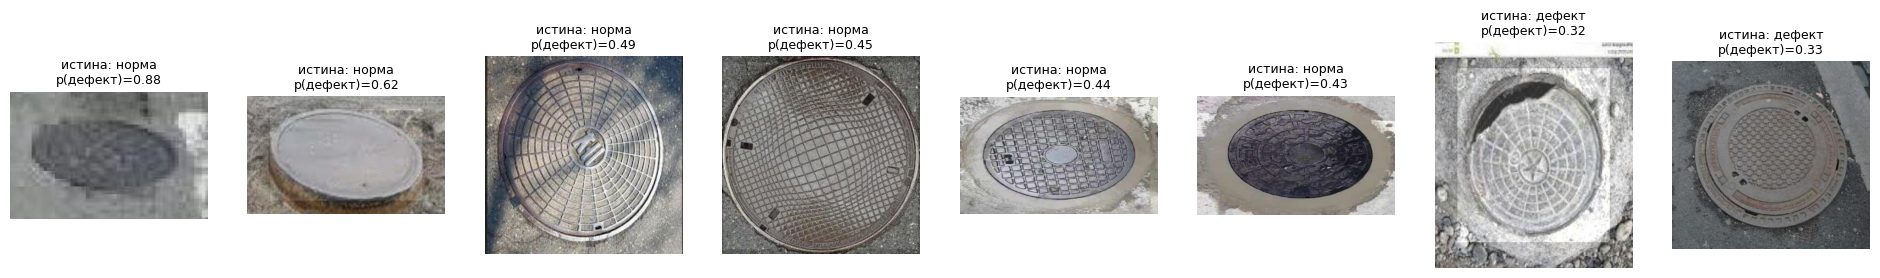

In [12]:
import matplotlib.pyplot as plt
wrong = np.where(pred != y)[0]
wrong = wrong[np.argsort(-np.abs(oof[wrong] - THR))][:8]
if len(wrong):
    fig, ax = plt.subplots(1, len(wrong), figsize=(3 * len(wrong), 3.4))
    ax = np.atleast_1d(ax)
    for a, i in zip(ax, wrong):
        a.imshow(imgs[i]); a.axis("off")
        a.set_title(f"истина: {'дефект' if y[i] else 'норма'}\np(дефект)={oof[i]:.2f}", fontsize=9)
    plt.show()
else:
    print("ошибок нет")

## 7. Финальная модель и функция для API

In [13]:
import joblib
final = LogisticRegression(C=best_C, class_weight="balanced", max_iter=3000).fit(X, y)
joblib.dump({"clf": final, "threshold": float(THR), "pad": PAD, "clip": MODEL_ID}, "/content/state_classifier.joblib")

def crop_with_pad(img: Image.Image, box_xyxy, pad=PAD):
    # вырезка по рамке детектора с тем же отступом, что и при обучении
    x1, y1, x2, y2 = box_xyxy; bw, bh = x2 - x1, y2 - y1
    W, H = img.size
    return img.crop((max(0, int(x1 - pad * bw)), max(0, int(y1 - pad * bh)),
                     min(W, int(x2 + pad * bw)), min(H, int(y2 + pad * bh))))

def classify(crop: Image.Image):
    p = float(final.predict_proba(embed([crop.convert("RGB")]))[0, 1])
    return {"status": "defect" if p >= THR else "ok", "p_defect": round(p, 3)}

# проверка
print(classify(imgs[int(np.where(y == 1)[0][0])]), classify(imgs[int(np.where(y == 0)[0][0])]))

{'status': 'defect', 'p_defect': 0.908} {'status': 'ok', 'p_defect': 0.176}


## Как стыковать с детектором
```python
for box in detections:                        # box = (x1, y1, x2, y2) в пикселях
    crop = crop_with_pad(image, box)
    result = classify(crop)                   # {'status': 'ok' | 'defect', 'p_defect': 0.xx}
```
Метрики считаются по группам, поэтому они честнее, чем разбиение train/valid из архива. Но выборка маленькая, поэтому смотрите не только на одно число, а и на разброс между значениями C и на разбор ошибок.